# 4.10 · Notebook 01 — Дані (data card, split)

**Проект:** виявлення аномалій у показах датчиків (варіант 4 — Anomaly detection).

У цьому notebook:
1. генеруємо відтворюваний synthetic dataset і зберігаємо його в `data/sensor_data.csv`;
2. описуємо дані (data card): схема, обсяг, мітки, типи аномалій;
3. фіксуємо **часовий** split train / validation / test і перевіряємо, що в ньому немає leakage.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pipeline import *

sns.set_theme(style="whitegrid", palette="muted")
cfg = load_config()
W = cfg["windows"]
WINDOWS_PER_DAY = cfg["data"]["points_per_day"] / W["step"]

## 1. Генерація даних

In [2]:
df = generate_sensor_data(cfg)
(Path("..") / "data").mkdir(exist_ok=True)
df.to_csv("../data/sensor_data.csv", index=False)
print("Збережено:", df.shape)
df.head()

Збережено: (17280, 6)


,timestamp,temperature,vibration,pressure,label,atype
0,2026-01-01 00:00:00,20.121887,1.010996,100.784371,0,
1,2026-01-01 00:10:00,19.802103,0.885227,99.558693,0,
2,2026-01-01 00:20:00,20.735959,0.939200,100.166053,0,
3,2026-01-01 00:30:00,21.028857,1.139028,101.329577,0,
4,2026-01-01 00:40:00,20.087827,1.122844,100.466638,0,


## 2. Data card

In [3]:
card = pd.Series({
    "Джерело": "synthetic, src/pipeline.py::generate_sensor_data (seed=%d)" % cfg["data"]["seed"],
    "Період": f'{df.timestamp.min():%Y-%m-%d} — {df.timestamp.max():%Y-%m-%d}',
    "Частота": "10 хв",
    "Рядків": len(df),
    "Канали": ", ".join(CHANNELS),
    "Частка аномальних точок": f'{df.label.mean():.1%}',
    "Чутливість даних": "немає (синтетичні дані)",
})
card.to_frame("значення")

,значення
Джерело,"synthetic, src/pipeline.py::generate_sensor_da..."
Період,2026-01-01 — 2026-04-30
Частота,10 хв
Рядків,17280
Канали,"temperature, vibration, pressure"
Частка аномальних точок,8.1%
Чутливість даних,немає (синтетичні дані)


In [4]:
df[CHANNELS].describe().round(2)

,temperature,vibration,pressure
count,17280.00,17280.00,17280.00
mean,20.07,1.00,100.05
std,3.61,0.17,2.89
min,-4.37,-0.14,83.56
25%,16.63,0.88,97.32
50%,20.04,1.00,100.02
75%,23.56,1.11,102.79
max,39.52,2.14,118.17


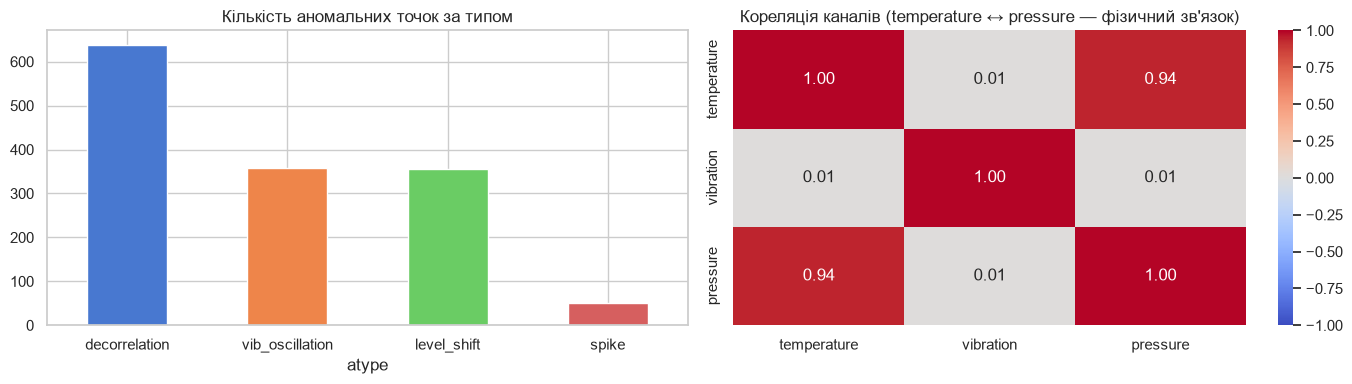

In [5]:
ev = df[df.label == 1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ev["atype"].value_counts().plot.bar(ax=axes[0], color=sns.color_palette("muted"), rot=0)
axes[0].set_title("Кількість аномальних точок за типом")
sns.heatmap(df[CHANNELS].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("Кореляція каналів (temperature ↔ pressure — фізичний зв'язок)")
plt.tight_layout(); plt.show()

### 2.1 Приклади кожного типу аномалії

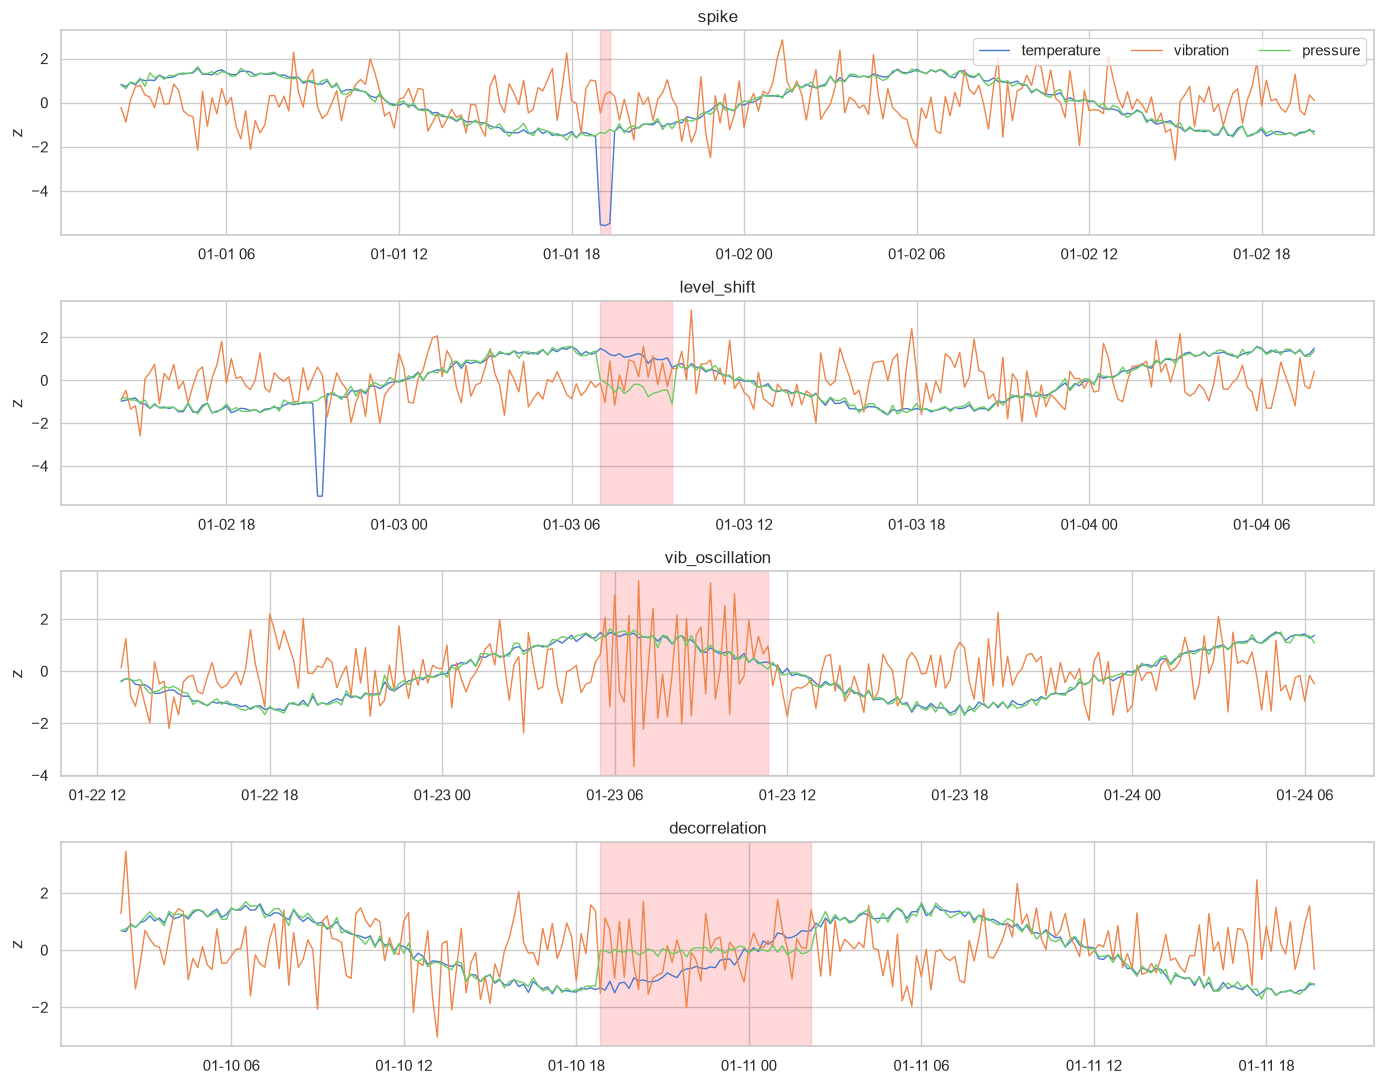

In [6]:
fig, axes = plt.subplots(len(ANOMALY_TYPES), 1, figsize=(14, 11))
for ax, kind in zip(axes, ANOMALY_TYPES):
    i = int(np.where(df.atype == kind)[0][0])
    seg = df.iloc[max(0, i - 100): i + 150]
    for ch in CHANNELS:
        z = (seg[ch] - df[ch].mean()) / df[ch].std()
        ax.plot(seg.timestamp, z, label=ch, lw=1)
    a = seg[seg.atype == kind]
    ax.axvspan(a.timestamp.min(), a.timestamp.max(), color="red", alpha=0.15)
    ax.set_title(f"{kind}"); ax.set_ylabel("z")
axes[0].legend(ncol=3, loc="upper right")
plt.tight_layout(); plt.show()

Видно, що **decorrelation** не виходить за межі нормального діапазону значень: тиск просто перестає слідувати за температурою. Простий поріг по амплітуді таку аномалію не побачить — саме тут очікуємо перевагу моделі, яка вчить **спільну структуру** каналів.

## 3. Split protocol

Часовий split без перемішування (60% / 20% / 20%): модель вчиться на минулому і перевіряється на майбутньому. Це чесніше для часових рядів, ніж випадковий split, бо сусідні вікна майже однакові.

In [7]:
tr, va, te = temporal_split(df, cfg)
split = pd.DataFrame({
    "part": ["train", "validation", "test"],
    "from": [p.timestamp.min() for p in (tr, va, te)],
    "to": [p.timestamp.max() for p in (tr, va, te)],
    "rows": [len(p) for p in (tr, va, te)],
    "anomaly_share": [p.label.mean().round(3) for p in (tr, va, te)],
})
split

,part,from,to,rows,anomaly_share
0,train,2026-01-01,2026-03-13 23:50:00,10368,0.063
1,validation,2026-03-14,2026-04-06 23:50:00,3456,0.134
2,test,2026-04-07,2026-04-30 23:50:00,3456,0.084


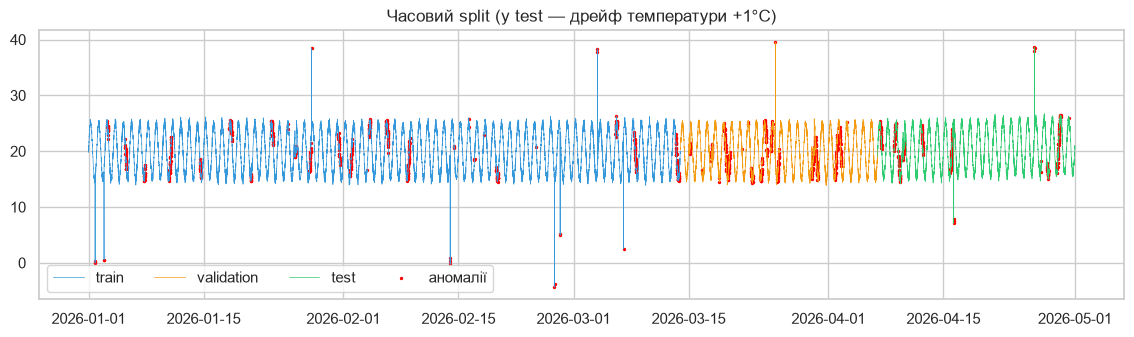

In [8]:
fig, ax = plt.subplots(figsize=(14, 3.5))
for p, c, n in [(tr, "#3498db", "train"), (va, "#f39c12", "validation"), (te, "#2ecc71", "test")]:
    ax.plot(p.timestamp, p.temperature, color=c, lw=0.5, label=n)
ax.scatter(df.timestamp[df.label == 1], df.temperature[df.label == 1], s=2, color="red", label="аномалії")
ax.set_title("Часовий split (у test — дрейф температури +1°C)"); ax.legend(ncol=4)
plt.show()

### 3.1 Перевірки leakage

In [9]:
assert tr.timestamp.max() < va.timestamp.min() < te.timestamp.min(), "перетин періодів!"
for name, part in [("train", tr), ("validation", va), ("test", te)]:
    Xw, yw, tw = make_windows(part, W["window"], W["step"])
    print(f"{name:<10} windows={len(Xw):4d}  anomalous={yw.mean():.2%}")
print("\nПеревірки пройдено: періоди не перетинаються, вікна будуються окремо в межах кожної частини.")
print("Scaler і модель навчаються лише на НОРМАЛЬНИХ вікнах train; поріг — на validation; test — один раз у кінці.")

train      windows=1723  anomalous=17.47%
validation windows= 571  anomalous=32.05%
test       windows= 571  anomalous=20.14%

Перевірки пройдено: періоди не перетинаються, вікна будуються окремо в межах кожної частини.
Scaler і модель навчаються лише на НОРМАЛЬНИХ вікнах train; поріг — на validation; test — один раз у кінці.
